**Exploratory Data Analysis(EDA)** is the process of:

*Understanding the data: Exploring its structure, columns, and data types.*

*Cleaning the data: Handling missing values, duplicates, and outliers.*

*Analyzing the data: Calculating summary statistics and identifying patterns.*

*Visualizing the data: Creating plots to uncover insights.*

In [110]:
#import neccessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [111]:
#Download data
df=sns.load_dataset('titanic')
#Understanding the data: Exploring its structure, columns, and data types.
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [112]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [114]:
#Cleaning the data: Handling missing values, duplicates, and outliers.
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [115]:
# For numerical features like 'age', fill missing values with the median.
df['age']=df['age'].fillna(df['age'].median())
# For categorical features like 'embarked' and 'deck', fill missing values with the mode.
df['embark_town']=df['embark_town'].fillna(df['embark_town'].mode()[0])
df['embarked']=df['embarked'].fillna(df['embarked'].mode()[0])
df['deck']=df['deck'].fillna(df['deck'].mode()[0])
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64

In [116]:
#Check for Duplicates and remove it
df.duplicated().sum()

np.int64(112)

In [117]:
df.drop_duplicates(inplace=True)

In [118]:
df.shape

(779, 15)

In [119]:
#Code to Remove Outliers Using IQR
# Select only numeric columns
numerical_data=df.select_dtypes(include=['int64', 'float64'])
# Calculate Q1, Q3, and IQR for each column
Q1=numerical_data.quantile(0.25)
Q3=numerical_data.quantile(0.75)
ICQ=Q3-Q1
# Define outlier limits
lower_bound=Q1-1.5*ICQ
upper_bound=Q3+1.5*ICQ
# Remove outliers
df=df[~((numerical_data<lower_bound) | (numerical_data>upper_bound)).any(axis=1)]
print("Data Shape After Removing Outliers:", df.shape)
# df.head()

Data Shape After Removing Outliers: (603, 15)


**Code to remove outliers using Z-Score**

*Calculate mean and standard deviation*
mean = np.mean(data)
std = np.std(data)

*Define threshold for Z-score*
Define an Outlier Threshold:

*Common thresholds: ∣z∣>2 (moderate outliers), ∣z∣>3 (extreme outliers)*

Filter out data points with ∣z∣>3 if using the ±3 threshold.

threshold = 3

*Calculate Z-scores*
z_scores = [(x - mean) / std for x in data]

*Filter out outliers*
filtered_data = [x for x, z in zip(data, z_scores) if abs(z) < threshold]

In [120]:
#Analyzing the data: Calculating summary statistics and identifying patterns.
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,603.000000,603.000000,603.000000,603.000000,603.000000,603.000000
mean,0.389718,2.409619,28.421227,0.305141,0.252073,18.152598
std,0.488091,0.762301,11.194878,0.524886,0.558363,14.359996
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,22.000000,0.000000,0.000000,7.895800
50%,0.000000,3.000000,28.000000,0.000000,0.000000,13.000000
75%,1.000000,3.000000,34.000000,1.000000,0.000000,26.000000
max,1.000000,3.000000,57.000000,2.000000,2.000000,71.283300


In [121]:
#Survival Rate by Gender
df.groupby("sex")["survived"].mean()

sex
female    0.724138
male      0.220000
Name: survived, dtype: float64

In [122]:
#Survival Rate by Class
df.groupby("class", observed=False)['survived'].mean()

class
First     0.568627
Second    0.526316
Third     0.277937
Name: survived, dtype: float64

In [123]:
#Correlation Matrix
numerical_data.corr()

,survived,pclass,age,sibsp,parch,fare
survived,1.000000,-0.331448,-0.077100,-0.038194,0.069175,0.247000
pclass,-0.331448,1.000000,-0.341432,0.088291,0.040335,-0.551719
age,-0.077100,-0.341432,1.000000,-0.279149,-0.182627,0.092358
sibsp,-0.038194,0.088291,-0.279149,1.000000,0.380385,0.134722
parch,0.069175,0.040335,-0.182627,0.380385,1.000000,0.191613
fare,0.247000,-0.551719,0.092358,0.134722,0.191613,1.000000


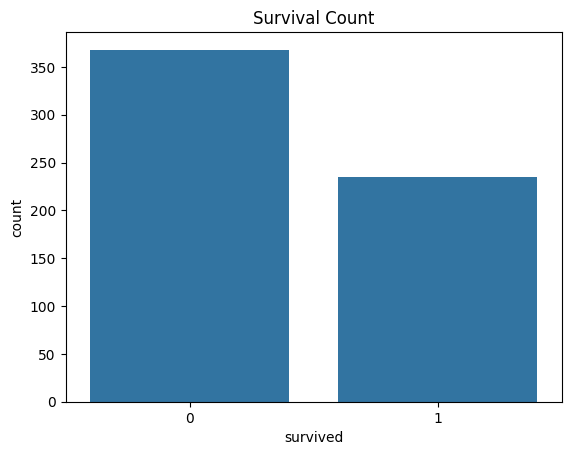

In [124]:
#Survival Count
sns.countplot(x="survived", data=df)
plt.title("Survival Count")
plt.show()

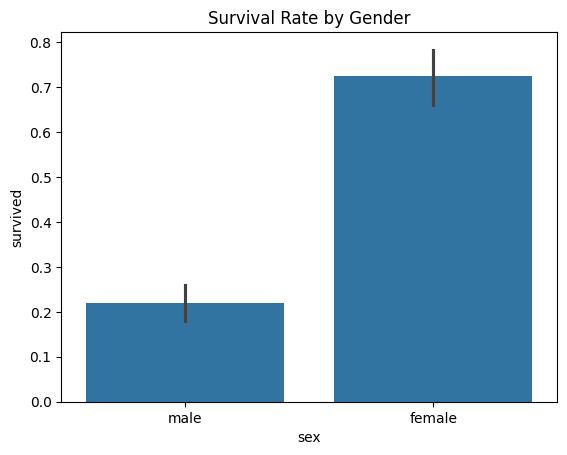

In [125]:
#Survival Rate by Gender
sns.barplot(x='sex', y='survived', data=df)
plt.title("Survival Rate by Gender")
plt.show()

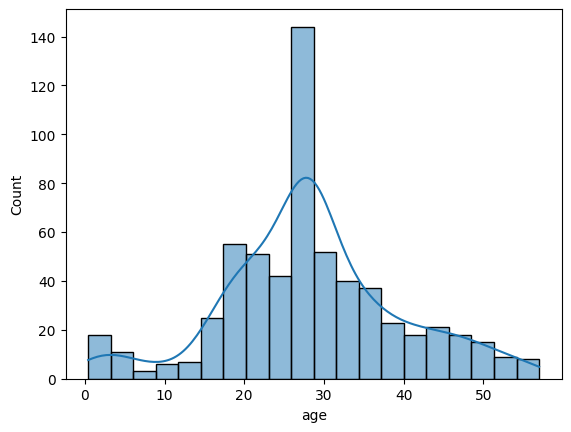

In [126]:
#Age Distribution
sns.histplot(df['age'], kde=True)
plt.show()

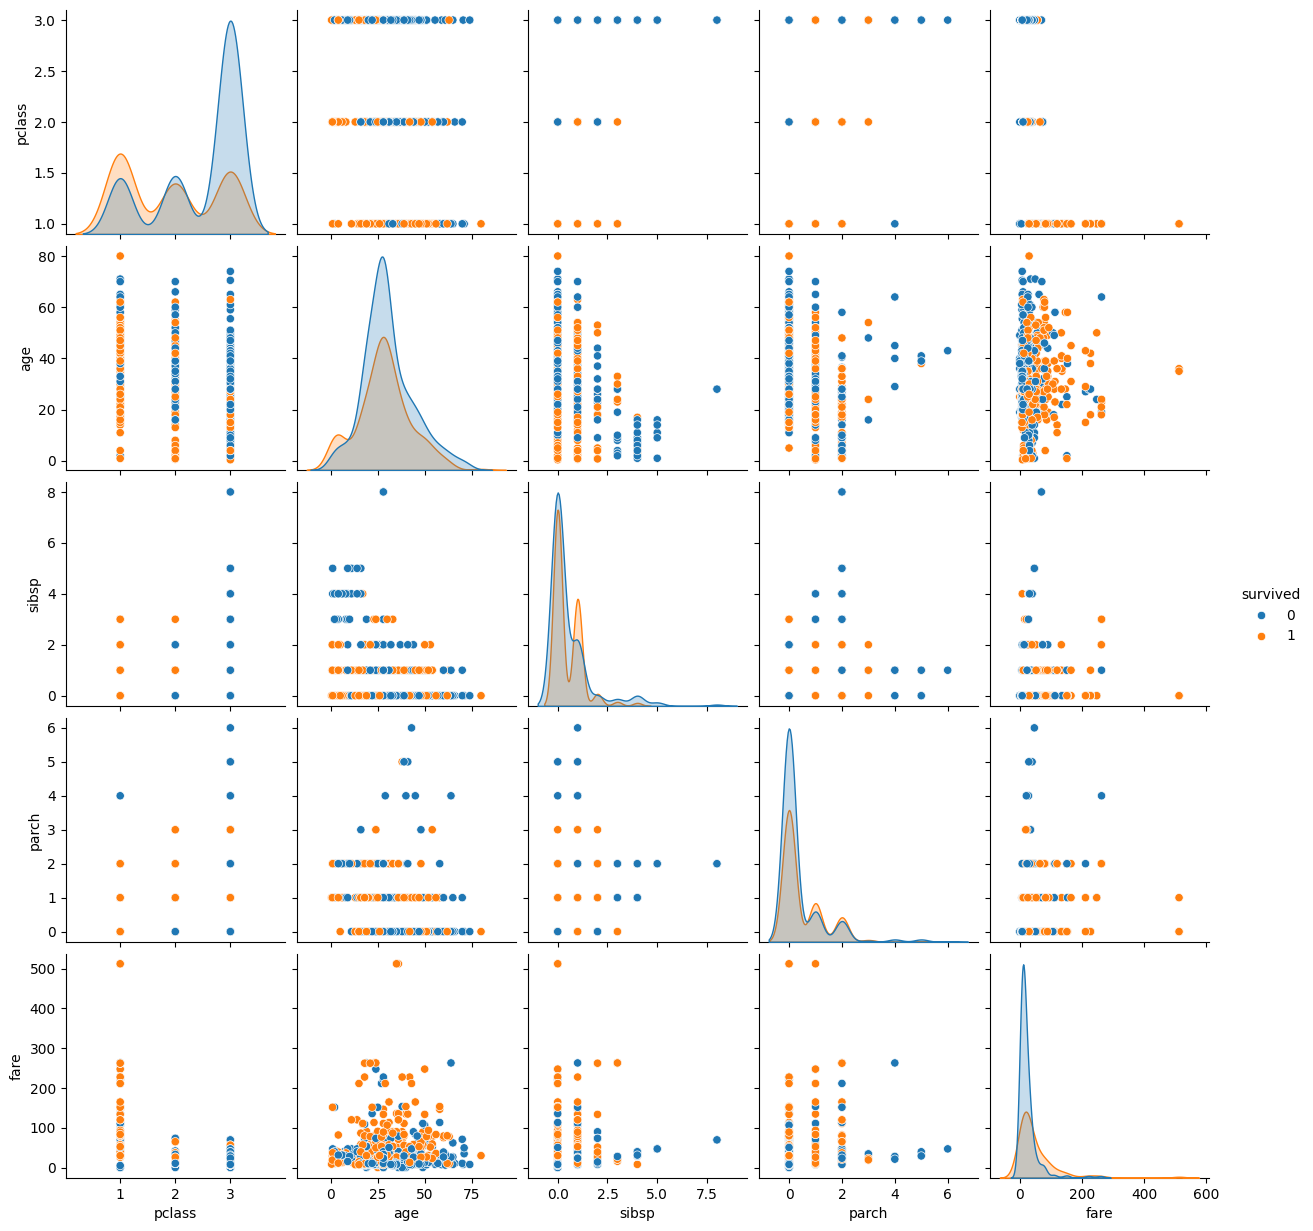

In [127]:
# Pair plot for numerical columns
sns.pairplot(numerical_data, hue='survived')
plt.show()